Import and setup

In [1]:
# config
from pathlib import Path
import sys
import datetime as Date
import json

# Nếu notebook nằm trong thư mục notebooks/
PROJECT_ROOT = Path.cwd().parent.parent
SRC_DIR = PROJECT_ROOT / "src"

sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)
print("Source exists:", SRC_DIR.exists())
print("Pipeline exists:", (SRC_DIR / "pipeline").is_dir())

from src.pipeline.logger import setup_logger, log_execution
from src.pipeline.reader import read_data, create_content_hash, read_sql

from src.pipeline.database import create_db_engine
from src.pipeline.executor import execute_sql, truncate_table, query_sql, insert_dataframe, insert_on_conflict_nothing

# database
DRY_RUN = False
ROLLBACK = False
engine = create_db_engine()

# schema init
execute_sql(
    engine,
    read_sql("bronze/schema/create_schema.sql"),
    DRY_RUN,
    ROLLBACK
)
print("Bronze schema created")

# table init
# ingestion
execute_sql(
    engine,
    read_sql("bronze/schema/create_ingestion.sql"),
    DRY_RUN,
    ROLLBACK,
)
# raw orders
execute_sql(
    engine,
    read_sql("bronze/schema/create_raw_orders.sql"),
    DRY_RUN,
    ROLLBACK,
)
# postal code
execute_sql(
    engine,
    read_sql("bronze/schema/create_postal_code.sql"),
    DRY_RUN,
    ROLLBACK,
)
# market
execute_sql(
    engine,
    read_sql("bronze/schema/create_market.sql"),
    DRY_RUN,
    ROLLBACK,
)
print("Ingestion table created")

Project root: d:\_HCMUT\_Nam4\k261\CO4031-Datawarehouse\Global-Superstore-warehouse-and-DSS
Source exists: True
Pipeline exists: True
Bronze schema created
Ingestion table created


Load file

In [2]:
# load file
logger = setup_logger(name="bronze",run_id="bronze_001")
source_name = "Global_Superstore.xls"
# source_name = "Sample-Superstore.csv"

@log_execution(logger)
def run_extract(file_path):
    return read_data(file_path)

df = run_extract(PROJECT_ROOT / "data/raw" / source_name)["data"]
content_hash = create_content_hash(PROJECT_ROOT / "data/raw" / source_name)
loaded_time = Date.datetime.now().strftime("%Y-%m-%d %H:%M:%S")
print(f"Data loaded at: {loaded_time}")
print(f"Content hash: {content_hash}")

print(df.head(5))
print(df.shape)

2026-11-12 01:12:45,268 | INFO | run_id=bronze_001 | Started: run_extract
2026-11-12 01:12:52,994 | INFO | run_id=bronze_001 | Succeeded: run_extract
2026-11-12 01:12:53,000 | INFO | run_id=bronze_001 | Finished: run_extract | duration=7.73s


Data loaded at: 2026-11-12 01:12:53
Content hash: 5cc6581be17e438a88f0c15edb8d65f17a87ffd7dc043f20b1eca0dc72d37d77
   Row ID        Order ID Order Date  Ship Date       Ship Mode Customer ID  \
0       1  MX-2014-143658 2014-10-02 2014-10-06  Standard Class    SC-20575   
1       2  MX-2012-155047 2012-10-15 2012-10-20  Standard Class    KW-16570   
2       3  MX-2012-155047 2012-10-15 2012-10-20  Standard Class    KW-16570   
3       4  MX-2012-155047 2012-10-15 2012-10-20  Standard Class    KW-16570   
4       5  MX-2012-155047 2012-10-15 2012-10-20  Standard Class    KW-16570   

    Customer Name   Segment           City             State  ...  \
0    Sonia Cooley  Consumer    Mexico City  Distrito Federal  ...   
1  Kelly Williams  Consumer  Dos Quebradas         Risaralda  ...   
2  Kelly Williams  Consumer  Dos Quebradas         Risaralda  ...   
3  Kelly Williams  Consumer  Dos Quebradas         Risaralda  ...   
4  Kelly Williams  Consumer  Dos Quebradas         Risaralda  ...

## EDA cơ bản

Sau khi đã load dữ liệu, khám phá nhanh: đếm số giá trị unique và phân phối doanh thu (`Sales`) theo các dimension **Segment**, **Market**, **Category**, **Sub-Category**.

In [13]:
# EDA setup
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.grid"] = False   # bỏ lưới (grid) trên biểu đồ

eda_df = df.copy()
# bronze đang lưu Sales dạng text -> ép về numeric trước khi tổng hợp
eda_df["Sales"] = pd.to_numeric(eda_df["Sales"], errors="coerce")


def eda_report(col, title, rotate=0, date_format=None):
    df = eda_df.copy()

    if date_format == "year":
        df[col] = pd.to_datetime(
            df[col], dayfirst=True, errors="coerce"
        ).dt.year

    elif date_format == "quarter":
        df[col] = (
            pd.to_datetime(df[col], dayfirst=True, errors="coerce")
            .dt.to_period("Q").astype(str)
        )

    elif date_format == "month_period":
        df[col] = (
            pd.to_datetime(df[col], dayfirst=True, errors="coerce")
            .dt.to_period("M").astype(str)
        )

    elif date_format == "month":
        df[col] = (
            pd.to_datetime(df[col], dayfirst=True, errors="coerce")
            .dt.month
        )

    if col not in df.columns or df[col].dropna().empty:
        print(f"Cột {col} không có dữ liệu, bỏ qua.")
        return None

    summary = (
        df.groupby(col, dropna=False)
        .agg(
            Rows=("Sales", "size"),
            Sales=("Sales", "sum"),
            Profit=("Profit", "sum"),
            **{"Avg Discount": ("Discount", "mean")}
        )
        .sort_values("Sales", ascending=False)
    )

    summary["Sales Share %"] = (
        summary["Sales"] / summary["Sales"].sum() * 100
    ).round(2)

    summary["Profit Margin %"] = (
        summary["Profit"] / summary["Sales"] * 100
    ).round(2)

    print(summary.to_string())

    # 2x2 charts
    fig, axes = plt.subplots(2, 2, figsize=(16, 10))
    axes = axes.flatten()

    metrics = [
        ("Sales", "Sales (triệu USD)", 1e6),
        ("Rows", "Number of Rows", 1),
        ("Profit", "Profit (triệu USD)", 1e6),
        ("Avg Discount", "Average Discount (%)", 1)
    ]

    # Với thời gian, sắp xếp theo thứ tự thời gian
    if date_format:
        summary = summary.sort_index()

    for ax, (metric, ylabel, divisor) in zip(axes, metrics):
        values = summary[metric] / divisor

        bars = ax.bar(
            range(len(values)), values,
            color="steelblue", edgecolor="none"
        )

        ax.set_title(metric)
        ax.set_ylabel(ylabel)
        ax.set_xticks(range(len(values)))
        ax.set_xticklabels(
            summary.index.astype(str),
            rotation=rotate,
            ha="right" if rotate else "center"
        )
        ax.grid(False)

        for bar, value in zip(bars, values):
            label = (
                f"{value:.1%}" if metric == "Avg Discount"
                else f"{value:,.1f}" if divisor == 1e6
                else f"{value:,.0f}"
            )
            ax.annotate(
                label,
                (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha="center", va="bottom", fontsize=8
            )

    fig.suptitle(f"Business Distribution by {title}", fontsize=15)
    plt.tight_layout()
    plt.show()

    return summary


### 1. Segment

              Rows         Sales        Profit  Avg Discount  Sales Share %  Profit Margin %
Segment                                                                                     
Consumer     26518  6.507949e+06  749239.78206      0.143602          51.48            11.51
Corporate    15429  3.824698e+06  441208.32866      0.142931          30.25            11.54
Home Office   9343  2.309855e+06  277009.18056      0.140897          18.27            11.99


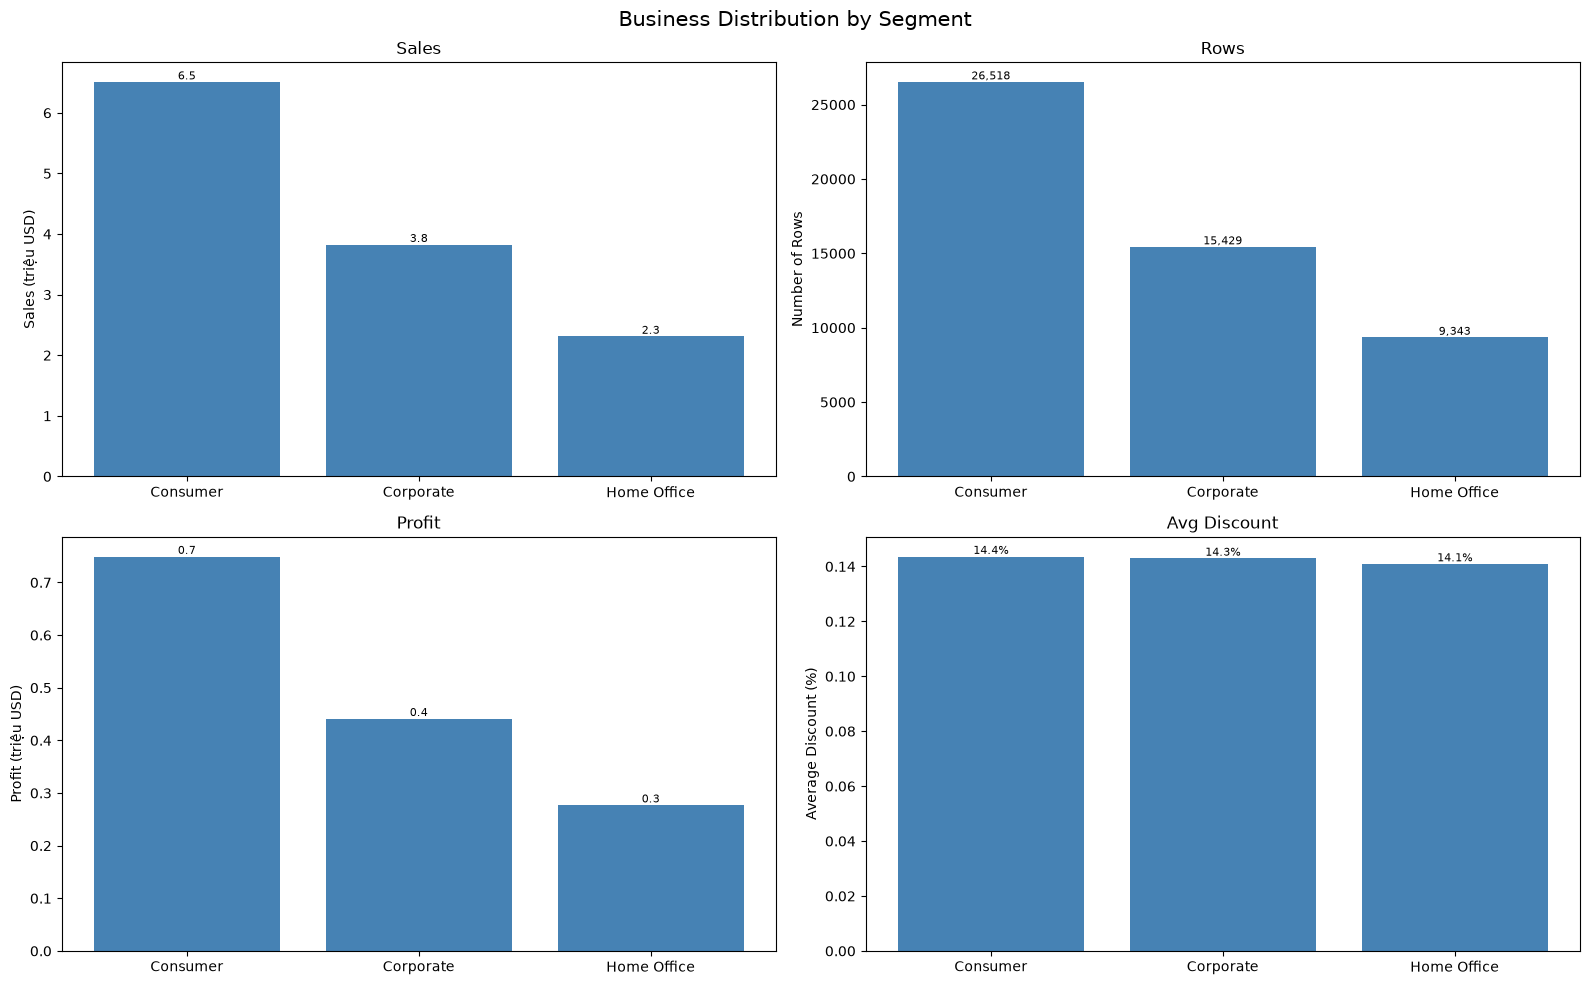

In [4]:
# 1) Segment - unique count + revenue distribution
segment_summary = eda_report("Segment", "Segment")


### 2. Market

         Rows         Sales        Profit  Avg Discount  Sales Share %  Profit Margin %
Market                                                                                 
APAC    11002  3.585744e+06  436000.04900      0.148839          28.36            12.16
EU      10000  2.938089e+06  372829.74150      0.103105          23.24            12.69
US       9994  2.297201e+06  286397.02170      0.156203          18.17            12.47
LATAM   10294  2.164605e+06  221643.48708      0.135531          17.12            10.24
EMEA     5029  8.061613e+05   43897.97100      0.196083           6.38             5.45
Africa   4587  7.837732e+05   88871.63100      0.156704           6.20            11.34
Canada    384  6.692817e+04   17817.39000      0.000000           0.53            26.62


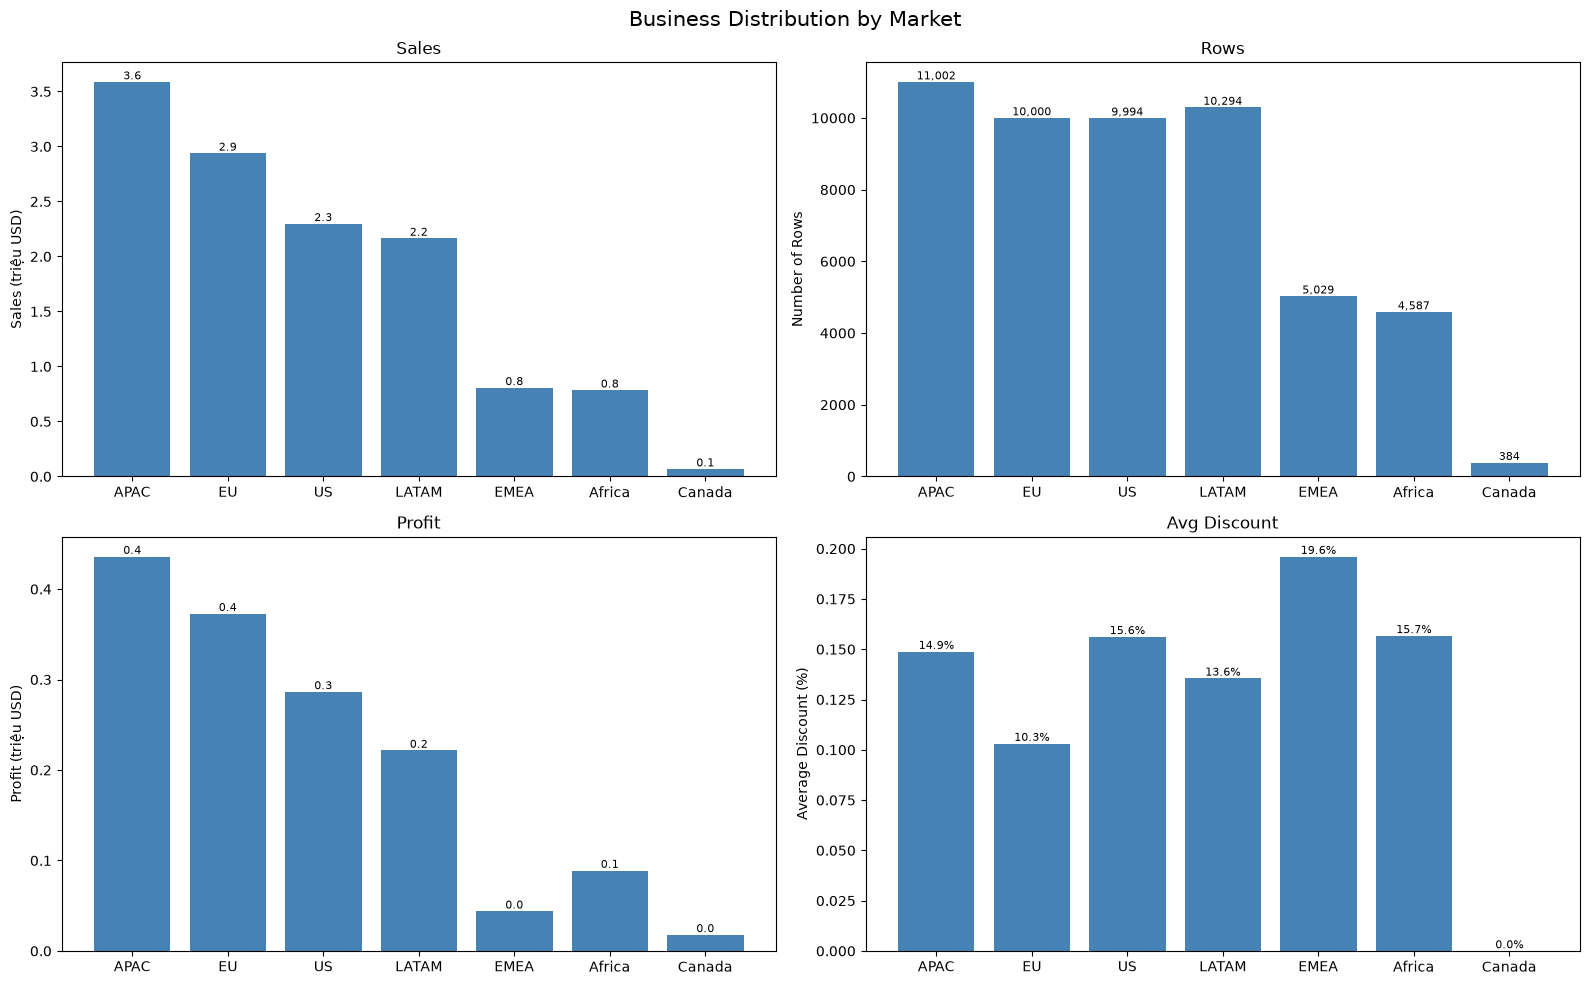

In [5]:
# 2) Market - unique count + revenue distribution
market_summary = eda_report("Market", "Market")


### 3. Category

                  Rows         Sales        Profit  Avg Discount  Sales Share %  Profit Margin %
Category                                                                                        
Technology       10141  4.744557e+06  663778.73318      0.135342          37.53            13.99
Furniture         9876  4.110874e+06  285204.72380      0.168087          32.52             6.94
Office Supplies  31273  3.787070e+06  518473.83430      0.137409          29.96            13.69


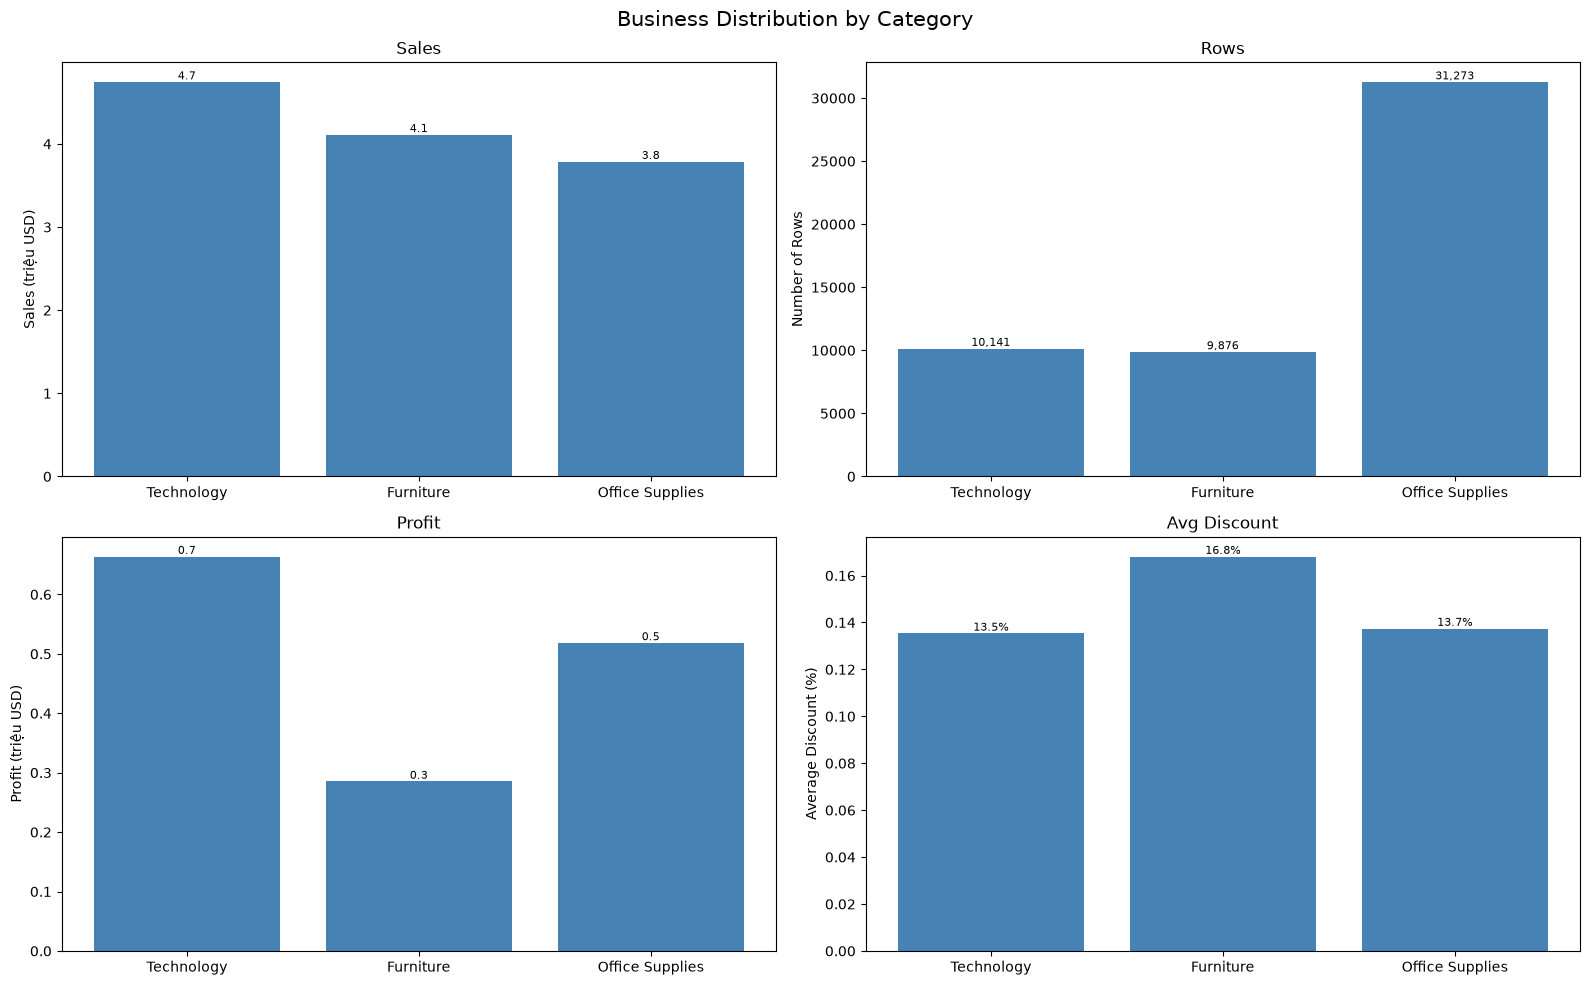

In [6]:
# 3) Category - unique count + revenue distribution
category_summary = eda_report("Category", "Category")


### 4. Sub-Category

              Rows         Sales        Profit  Avg Discount  Sales Share %  Profit Margin %
Sub-Category                                                                                
Phones        3357  1.706824e+06  216717.00580      0.145847          13.50            12.70
Copiers       2223  1.509436e+06  258567.54818      0.117147          11.94            17.13
Chairs        3434  1.501682e+06  140396.26750      0.163110          11.88             9.35
Bookcases     2411  1.466572e+06  161924.41950      0.153758          11.60            11.04
Storage       5059  1.127086e+06  108461.48980      0.138464           8.92             9.62
Appliances    1755  1.011064e+06  141680.58940      0.141709           8.00            14.01
Machines      1486  7.790601e+05   58867.87300      0.169583           6.16             7.56
Tables         861  7.570419e+05  -64083.38870      0.290732           5.99            -8.46
Accessories   3075  7.492370e+05  129626.30620      0.120481          

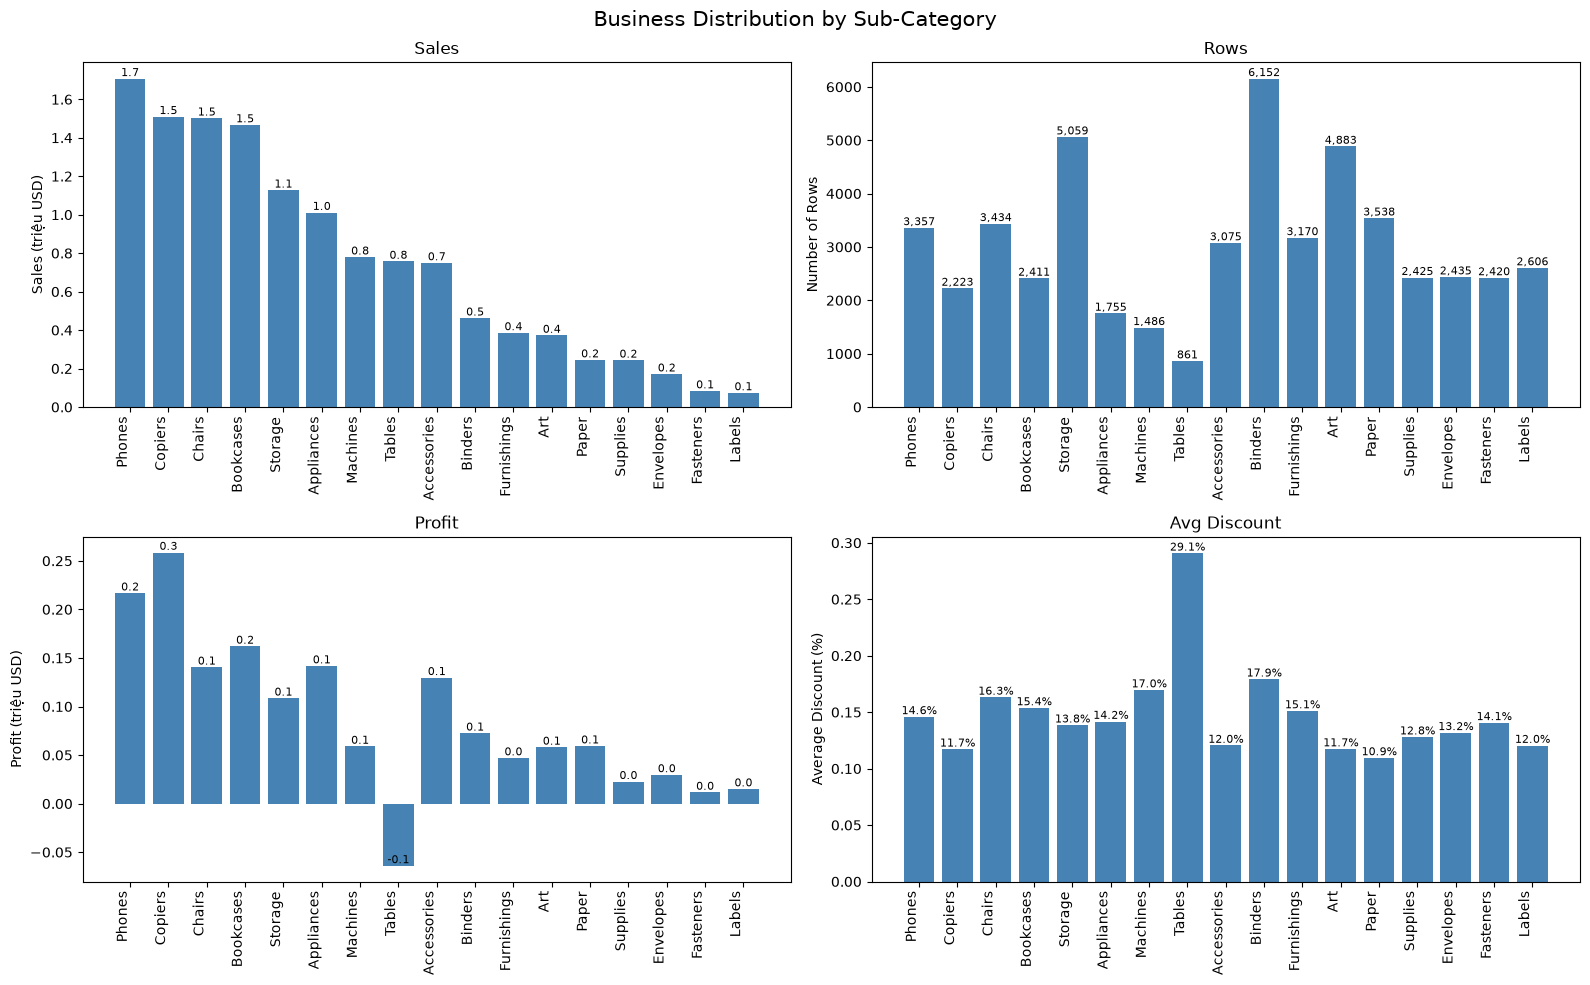

In [7]:
# 4) Sub-Category - unique count + revenue distribution
subcategory_summary = eda_report("Sub-Category", "Sub-Category", rotate=90)


             Rows         Sales        Profit  Avg Discount  Sales Share %  Profit Margin %
Order Date                                                                                 
2014        17531  4.299866e+06  504165.97046      0.143291          34.01            11.73
2013        13799  3.405746e+06  406935.23018      0.140265          26.94            11.95
2012        10962  2.677439e+06  307415.27910      0.141286          21.18            11.48
2011         8998  2.259451e+06  248940.81154      0.148188          17.87            11.02


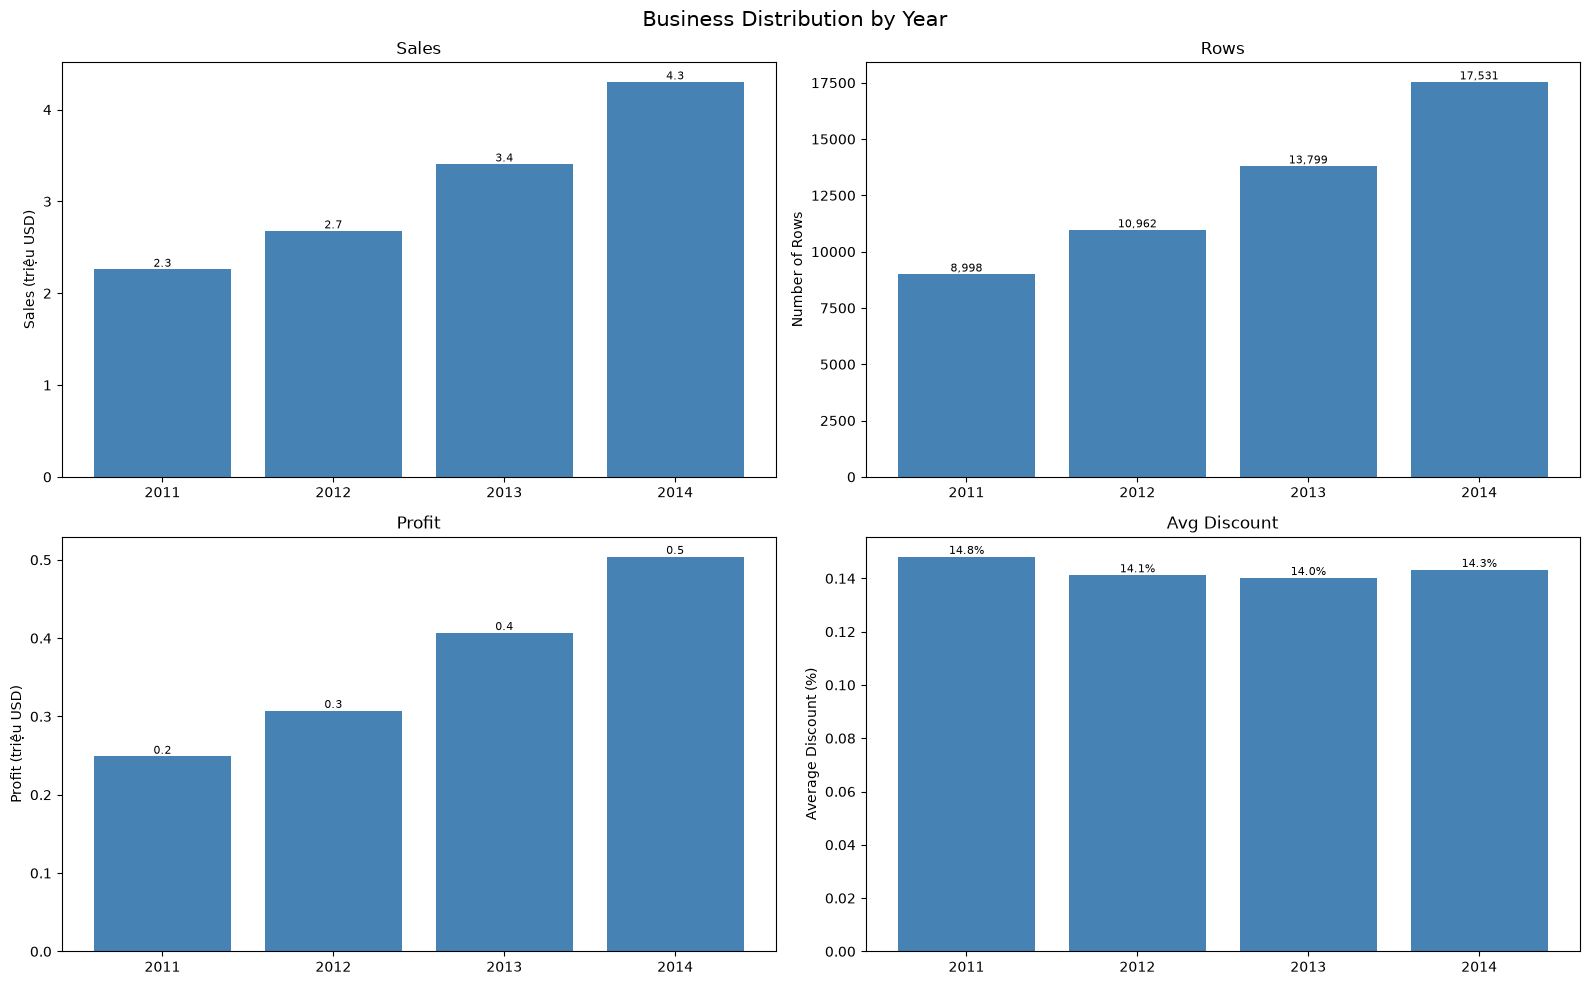

            Rows         Sales        Profit  Avg Discount  Sales Share %  Profit Margin %
Order Date                                                                                
2014Q4      5926  1.481189e+06  167982.94334      0.147358          11.72            11.34
2014Q3      4780  1.196483e+06  149558.21864      0.136669           9.46            12.50
2013Q4      4298  1.072850e+06  140699.09040      0.139571           8.49            13.11
2013Q3      4049  9.330370e+05   98793.16344      0.140518           7.38            10.59
2014Q2      4083  9.329870e+05  101514.46174      0.148040           7.38            10.88
2012Q4      3734  9.147092e+05   95434.35580      0.140442           7.24            10.43
2013Q2      3372  8.348395e+05   93436.14594      0.143194           6.60            11.19
2011Q4      3176  8.314935e+05   99320.58006      0.149952           6.58            11.94
2012Q3      2965  7.377689e+05   86935.44734      0.138159           5.84            11.78

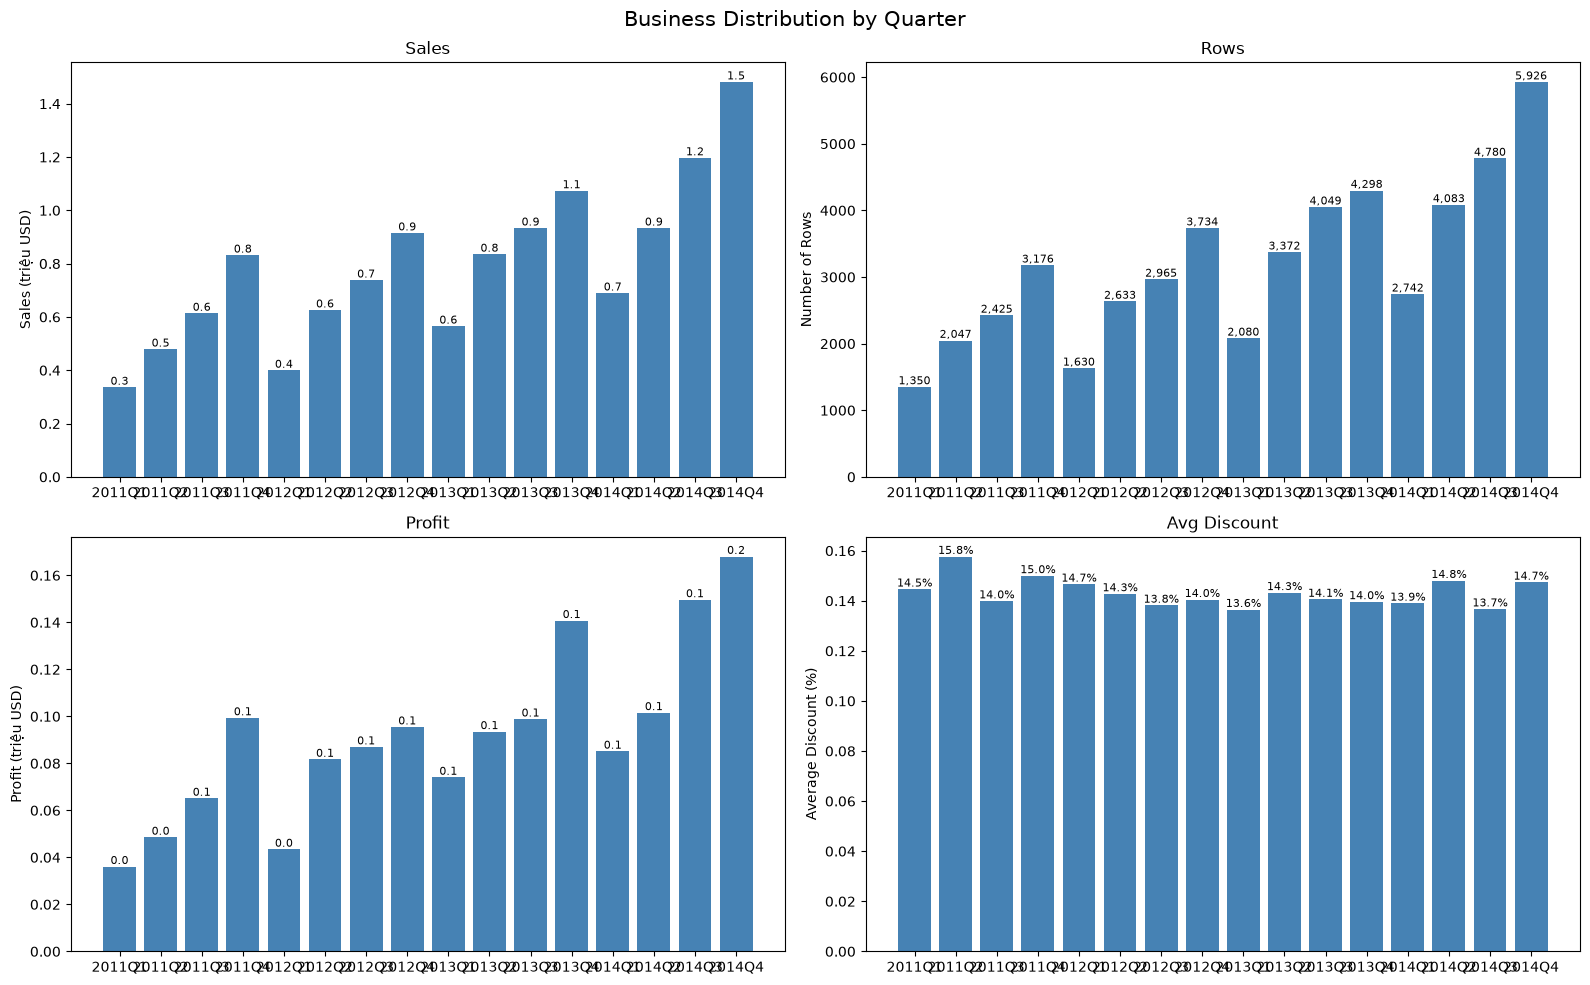

            Rows         Sales       Profit  Avg Discount  Sales Share %  Profit Margin %
Order Date                                                                               
2014-11     2147  555279.02700  62856.58790      0.141772           4.39            11.32
2014-12     2153  503143.69348  46916.52068      0.155646           3.98             9.32
2014-09     2018  481157.24370  67979.45110      0.134833           3.81            14.13
2014-08     1675  456619.94236  53542.89496      0.129953           3.61            11.73
2014-10     1626  422766.62916  58209.83476      0.143759           3.34            13.77
2013-12     1602  405454.37802  50202.87112      0.139633           3.21            12.38
2014-06     1748  401814.06310  43778.60280      0.143857           3.18            10.90
2013-06     1530  396519.61190  45478.41340      0.139635           3.14            11.47
2013-09     1682  376619.24568  38905.66778      0.143088           2.98            10.33
2013-11   

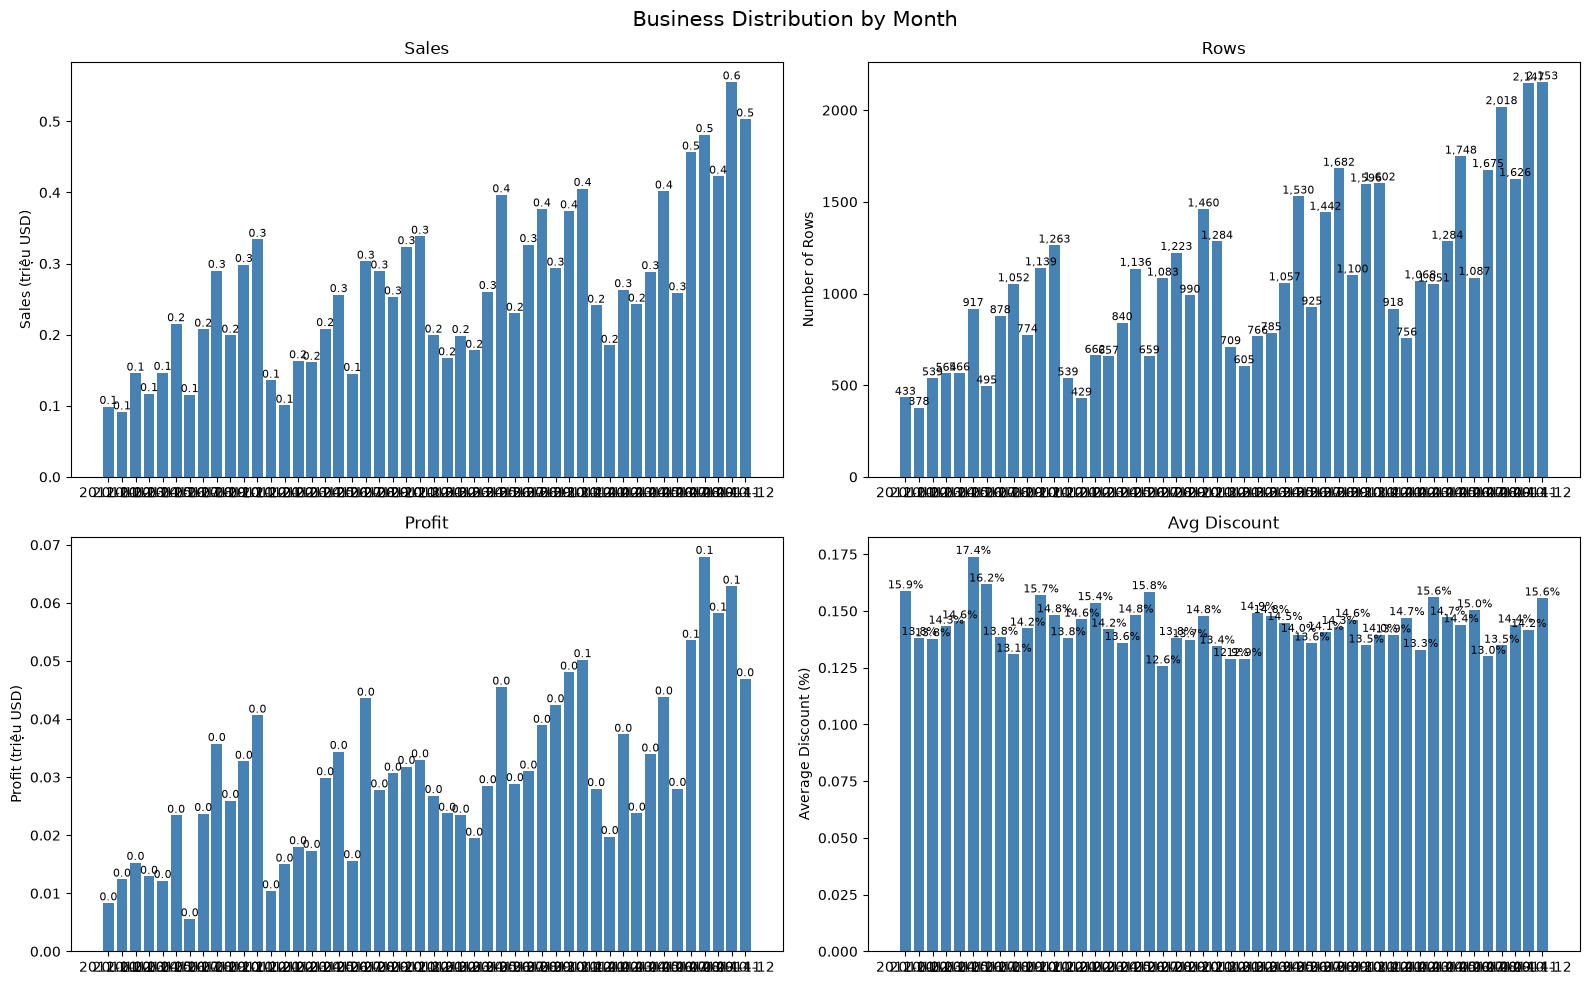

In [16]:
# 5) Time - unique count + revenue distribution
year_summary = eda_report("Order Date", "Year", date_format="year")

quarter_summary = eda_report("Order Date", "Quarter", date_format="quarter")

month_summary = eda_report("Order Date", "Month", date_format="month_period")

### Tổng hợp

In [9]:
# Tổng hợp nhanh: số unique value + doanh thu theo từng dimension
dims = ["Segment", "Market", "Category", "Sub-Category"]
overview = pd.DataFrame(
    [
        {
            "column": d,
            "unique": eda_df[d].nunique(dropna=True),
            "rows": int(eda_df[d].notna().sum()),
            "sales": eda_df.groupby(d)["Sales"].sum().sum(),
        }
        for d in dims
        if d in eda_df.columns and eda_df[d].dropna().any()
    ]
)
overview["share %"] = (overview["sales"] / overview["sales"].sum() * 100).round(2)
overview.style.format({"sales": "{:,.0f}", "share %": "{:.2f}%"})


,column,unique,rows,sales,share %
0,Segment,3,51290,"12,642,502",25.00%
1,Market,7,51290,"12,642,502",25.00%
2,Category,3,51290,"12,642,502",25.00%
3,Sub-Category,17,51290,"12,642,502",25.00%


## Data quality

### 5.1. Unique value - lower/upper case lẫn lộn?

In [10]:
# 5.1) Data quality - case consistency của các cột categorical
# Nếu sau khi lower() mà số unique giảm -> các giá trị đang lẫn lower/upper case
cat_cols = eda_df.select_dtypes(include=["object", "string"]).columns.tolist()

case_rows = []
for c in cat_cols:
    s = eda_df[c].dropna().astype(str)
    if s.empty:
        continue
    n_raw = s.nunique()
    n_lower = s.str.lower().nunique()
    n_upper = s.str.upper().nunique()
    case_rows.append({
        "column": c,
        "unique": n_raw,
        "unique_after_lower": n_lower,
        "unique_after_upper": n_upper,
        "case_mixed": n_raw != n_lower,
        "has_whitespace_gap": n_raw != s.str.strip().nunique(),
    })

case_df = pd.DataFrame(case_rows)
if case_df.empty:
    print("Không có cột categorical nào để kiểm tra.")
else:
    case_df = case_df.sort_values(["case_mixed", "unique"], ascending=[False, False])
    display(case_df)

mixed_cols = case_df.loc[case_df["case_mixed"], "column"].tolist() if not case_df.empty else []
print(f"Cột lẫn case: {mixed_cols if mixed_cols else 'Không có'}")

# in ví dụ các giá trị chỉ khác nhau về chữ hoa/thường
for c in mixed_cols:
    s = pd.DataFrame({"v": eda_df[c].dropna().astype(str)})
    grouped = s.groupby(s["v"].str.lower())["v"].unique()
    conflicts = {k: list(v) for k, v in grouped.items() if len(v) > 1}
    print(f"\n{c}: {len(conflicts)} nhóm xung đột, ví dụ:")
    for k, v in list(conflicts.items())[:5]:
        print(f"  {k!r} -> {v}")


,column,unique,unique_after_lower,unique_after_upper,case_mixed,has_whitespace_gap
0,Order ID,25035,25035,25035,False,False
10,Product ID,10292,10292,10292,False,False
13,Product Name,3788,3788,3788,False,False
5,City,3636,3636,3636,False,False
2,Customer ID,1590,1590,1590,False,False
6,State,1094,1094,1094,False,False
3,Customer Name,795,795,795,False,False
7,Country,147,147,147,False,False
12,Sub-Category,17,17,17,False,False
9,Region,13,13,13,False,False


Cột lẫn case: Không có


### 5.2. Null / Unknown - tỉ lệ thiếu theo cột

In [11]:
# 5.2) Data quality - tỉ lệ null / unknown theo từng cột
MISSING_TOKENS = {"", "unknown", "n/a", "na", "none", "null", "nil", "-", "no data"}


def missing_rate(series):
    """Trả về (số giá trị thiếu, mask) - thiếu = null hoặc token 'unknown'."""
    if pd.api.types.is_numeric_dtype(series) or pd.api.types.is_datetime64_any_dtype(series):
        mask = series.isna()
    else:
        norm = series.astype("string").str.strip().str.lower()
        mask = series.isna() | norm.isin(MISSING_TOKENS)
    return int(mask.sum()), mask


dq_rows = []
for c in eda_df.columns:
    n_missing, _ = missing_rate(eda_df[c])
    dq_rows.append({
        "column": c,
        "dtype": str(eda_df[c].dtype),
        "null": int(eda_df[c].isna().sum()),
        "unknown": n_missing - int(eda_df[c].isna().sum()),
        "missing": n_missing,
        "missing %": round(n_missing / len(eda_df) * 100, 2),
    })

dq_df = pd.DataFrame(dq_rows).sort_values("missing", ascending=False)
dq_df["status"] = dq_df["missing %"].apply(lambda p: "OK" if p == 0 else ("REVIEW" if p < 5 else "HIGH"))

print("Cột có giá trị thiếu:")
display(dq_df[dq_df["missing"] > 0])
print("Cột sạch (0% thiếu):", dq_df.loc[dq_df["missing"] == 0, "column"].tolist())
print()
print(dq_df["status"].value_counts().to_string())


Cột có giá trị thiếu:


,column,dtype,null,unknown,missing,missing %,status
11,Postal Code,float64,41296,0,41296,80.51,HIGH


Cột sạch (0% thiếu): ['Row ID', 'Order Date', 'Order ID', 'Ship Mode', 'Customer ID', 'Customer Name', 'Ship Date', 'Segment', 'City', 'State', 'Country', 'Market', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit', 'Shipping Cost', 'Order Priority']

status
OK      23
HIGH     1


### 5.3. Format ngày tháng

In [12]:
# 5.3) Data quality - format ngày tháng
DATE_CANDIDATES = ["%Y-%m-%d", "%d/%m/%Y", "%m/%d/%Y", "%d-%m-%Y", "%Y/%m/%d", "%d %b %Y", "%B %d, %Y"]

for c in ["Order Date", "Ship Date"]:
    if c not in eda_df.columns:
        print(f"{c}: cột không tồn tại")
        continue

    s = eda_df[c]
    print(f"[{c}] dtype = {s.dtype} | nulls = {int(s.isna().sum())}")

    if pd.api.types.is_datetime64_any_dtype(s):
        parsed = s
        print("  -> đã là datetime, không cần parse lại")
    else:
        sample = s.dropna().astype(str)
        print("  sample:", sample.head(3).tolist())

        parsed = pd.to_datetime(s, errors="coerce")          # pandas tự đoán
        fmt_found = None
        for fmt in DATE_CANDIDATES:                          # thử format cụ thể
            trial = pd.to_datetime(sample, format=fmt, errors="coerce")
            if trial.notna().all():
                fmt_found = fmt
                break
        print(f"  -> format suy đoán: {fmt_found or 'không xác định được (dùng dateutil)'}")

    unparsed = int(parsed.isna().sum() - s.isna().sum())
    print(f"  -> giá trị parse lỗi: {unparsed}")
    print(f"  -> range: {parsed.min()} .. {parsed.max()}")

# kiểm tra logic: ngày ship không được trước ngày order
if {"Order Date", "Ship Date"}.issubset(eda_df.columns):
    od = pd.to_datetime(eda_df["Order Date"], errors="coerce")
    sd = pd.to_datetime(eda_df["Ship Date"], errors="coerce")
    bad_ship = int((sd < od).sum())
    print(f"\nShip Date < Order Date: {bad_ship} dòng")
    print(f"Khoảng thời gian giao (ngày): min={(sd - od).dt.days.min()} | "
          f"max={(sd - od).dt.days.max()} | mean={(sd - od).dt.days.mean():.1f}")


[Order Date] dtype = datetime64[us] | nulls = 0
  -> đã là datetime, không cần parse lại
  -> giá trị parse lỗi: 0
  -> range: 2011-01-01 00:00:00 .. 2014-12-31 00:00:00
[Ship Date] dtype = datetime64[us] | nulls = 0
  -> đã là datetime, không cần parse lại
  -> giá trị parse lỗi: 0
  -> range: 2011-01-03 00:00:00 .. 2015-01-07 00:00:00

Ship Date < Order Date: 0 dòng
Khoảng thời gian giao (ngày): min=0 | max=7 | mean=4.0
